RIDGE REGRESSION (TARGET FEATURE = worst negative slack)

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("/content/model_a_train_combined.csv")
val = pd.read_csv("/content/model_a_validation_combined.csv")
test = pd.read_csv("/content/model_a_test_combined.csv")

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

assert list(train.columns) == list(val.columns) == list(test.columns)

# Check that architectures are disjoint
assert set(train["architecture"]).isdisjoint(val["architecture"])
assert set(train["architecture"]).isdisjoint(test["architecture"])
assert set(val["architecture"]).isdisjoint(test["architecture"])

# Check that RTL hashes are disjoint
assert set(train["rtl_sha256"]).isdisjoint(val["rtl_sha256"])
assert set(train["rtl_sha256"]).isdisjoint(test["rtl_sha256"])

print("Architecture and RTL separation verified!")


Train: (1367, 82)
Validation: (294, 82)
Test: (289, 82)
Architecture and RTL separation verified!


In [5]:

TARGET = "worst_slack_ns"

# Everything before the first target is input-side data
target_start = train.columns.get_loc(
    "critical_path_data_arrival_ns"
)

input_columns = list(train.columns[:target_start])

# Select numeric predictive features only
feature_columns = [
    col for col in input_columns
    if pd.api.types.is_numeric_dtype(train[col])
    and col != "sample_id"
]

X_train = train[feature_columns].copy()
X_val = val[feature_columns].copy()

y_train = train[TARGET].copy()
y_val = val[TARGET].copy()

print("Number of numeric features:", len(feature_columns))
print("Missing input values:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])
print("Missing WNS targets:", y_train.isna().sum())

assert y_train.notna().all()
assert y_val.notna().all()


Number of numeric features: 47
Missing input values:
net_max_reg_to_reg_cell_depth     80
rtl_memory_depth_words           764
dtype: int64
Missing WNS targets: 0


In [6]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ridge = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True,
        keep_empty_features=True
    )),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge.fit(X_train, y_train)

train_pred = ridge.predict(X_train)
val_pred = ridge.predict(X_val)

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

print("Training:", evaluate(y_train, train_pred))
print("Validation:", evaluate(y_val, val_pred))


Training: {'MAE': 0.21836974145301152, 'RMSE': np.float64(0.337708384245153), 'R2': 0.9922306152314461}
Validation: {'MAE': 0.4068557032678569, 'RMSE': np.float64(0.7524688215601855), 'R2': 0.9716667812536968}


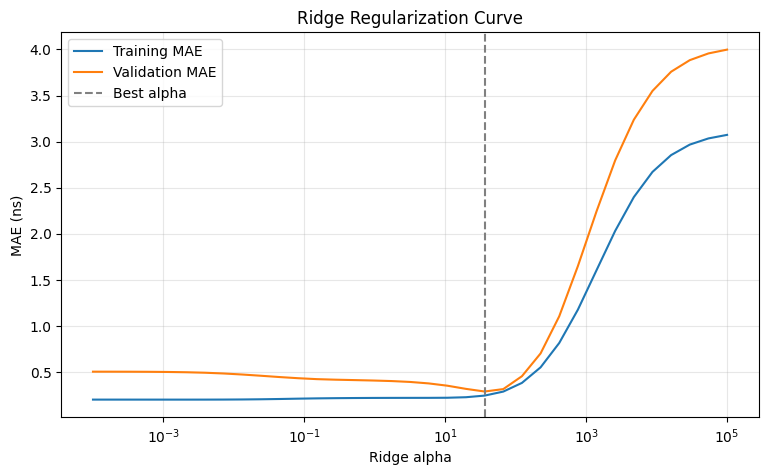

Best alpha: 36.20958350245917


In [7]:

alphas = np.logspace(-4, 5, 35)

train_mae = []
val_mae = []

for alpha in alphas:
    ridge.set_params(model__alpha=alpha)
    ridge.fit(X_train, y_train)

    train_mae.append(
        mean_absolute_error(y_train, ridge.predict(X_train))
    )
    val_mae.append(
        mean_absolute_error(y_val, ridge.predict(X_val))
    )

plt.figure(figsize=(9, 5))
plt.semilogx(alphas, train_mae, label="Training MAE")
plt.semilogx(alphas, val_mae, label="Validation MAE")
plt.axvline(
    alphas[np.argmin(val_mae)],
    linestyle="--",
    color="gray",
    label="Best alpha"
)
plt.xlabel("Ridge alpha")
plt.ylabel("MAE (ns)")
plt.title("Ridge Regularization Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_alpha = alphas[np.argmin(val_mae)]
print("Best alpha:", best_alpha)


The cell below is to test how much of the generalization is happening due to actual learning of the workings of the circuit, and how much due to memorising the relationship between clock period and worst negative slack.

In [8]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# Only clock period as the predictor
clock_train = X_train[["clock_period_ns"]]
clock_val = X_val[["clock_period_ns"]]

clock_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_alpha)
)

clock_model.fit(clock_train, y_train)

clock_train_pred = clock_model.predict(clock_train)
clock_val_pred = clock_model.predict(clock_val)

# Refit full model at the best alpha
ridge.set_params(model__alpha=best_alpha)
ridge.fit(X_train, y_train)

full_train_pred = ridge.predict(X_train)
full_val_pred = ridge.predict(X_val)

print("CLOCK-ONLY RIDGE")
print("Train MAE:", mean_absolute_error(y_train, clock_train_pred))
print("Validation MAE:", mean_absolute_error(y_val, clock_val_pred))

print("\nFULL-FEATURE RIDGE")
print("Train MAE:", mean_absolute_error(y_train, full_train_pred))
print("Validation MAE:", mean_absolute_error(y_val, full_val_pred))


CLOCK-ONLY RIDGE
Train MAE: 0.44808925717937836
Validation MAE: 0.5687142422846653

FULL-FEATURE RIDGE
Train MAE: 0.24360593393348778
Validation MAE: 0.2879869684901385


In [9]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Full Ridge model at the selected alpha
ridge.set_params(model__alpha=best_alpha)
ridge.fit(X_train, y_train)

pred = ridge.predict(X_val)

# Actual and predicted violations
actual_violation = (y_val.to_numpy() < 0).astype(int)
predicted_violation = (pred < 0).astype(int)

print("Violation classification:")
print(classification_report(
    actual_violation,
    predicted_violation,
    target_names=["Timing met", "Violation"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    actual_violation,
    predicted_violation
))

# Separate MAE for violated and nonviolated designs
actual = y_val.to_numpy()

for name, mask in [
    ("Actual violations", actual < 0),
    ("Timing met", actual >= 0)
]:
    print(
        name,
        "MAE:",
        mean_absolute_error(actual[mask], pred[mask])
    )


Violation classification:
              precision    recall  f1-score   support

  Timing met       0.99      0.89      0.94       221
   Violation       0.75      0.99      0.85        73

    accuracy                           0.91       294
   macro avg       0.87      0.94      0.90       294
weighted avg       0.93      0.91      0.92       294

Confusion matrix:
[[197  24]
 [  1  72]]
Actual violations MAE: 0.1482994504371435
Timing met MAE: 0.33412809436284724


To see where the false positives are clustering (if near zero slack, or if at high positive slack)

In [10]:

import numpy as np
import pandas as pd

actual = y_val.to_numpy()
predicted = ridge.predict(X_val)

diagnostics = val[
    ["design", "architecture", "clock_period_ns"]
].copy()

diagnostics["actual_wns"] = actual
diagnostics["predicted_wns"] = predicted
diagnostics["error_ns"] = predicted - actual

diagnostics["actual_violation"] = actual < 0
diagnostics["predicted_violation"] = predicted < 0

false_negatives = diagnostics[
    diagnostics["actual_violation"]
    & ~diagnostics["predicted_violation"]
]

false_positives = diagnostics[
    ~diagnostics["actual_violation"]
    & diagnostics["predicted_violation"]
]

print("MISSED VIOLATIONS")
display(false_negatives)

print("\nFALSE ALARMS")
display(
    false_positives.sort_values(
        "error_ns"
    )
)


MISSED VIOLATIONS


,design,architecture,clock_period_ns,actual_wns,predicted_wns,error_ns,actual_violation,predicted_violation
2,batch_multiplier_behavioral_w8_s01,multiplier_behavioral,0.9039,-0.2,0.480112,0.680112,True,False



FALSE ALARMS


,design,architecture,clock_period_ns,actual_wns,predicted_wns,error_ns,actual_violation,predicted_violation
260,v5__sequential__timer__w32__v5_p05,timer,1.8774,0.5364,-0.459323,-0.995723,False,True
259,v5__sequential__timer__w32__v5_p04,timer,1.5421,0.2011,-0.788067,-0.989167,False,True
258,v5__sequential__timer__w32__v5_p03,timer,1.3410,0.0000,-0.985235,-0.985235,False,True
155,v4__add_sub__w64__s1__v4_p04,add_sub,3.5500,0.4630,-0.022654,-0.485654,False,True
154,v4__add_sub__w64__s1__v4_p03,add_sub,3.0870,0.0000,-0.476602,-0.476602,False,True
130,v4__add_sub__w32__s1__v4_p03,add_sub,1.7786,0.0000,-0.233435,-0.233435,False,True
243,v5__sequential__fsm_moore__w8__v5_p04,fsm_moore,0.8969,0.1170,-0.087741,-0.204741,False,True
242,v5__sequential__fsm_moore__w8__v5_p03,fsm_moore,0.7799,0.0000,-0.202454,-0.202454,False,True
146,v4__add_sub__w32__s3__v4_p03,add_sub,1.9835,0.0000,-0.187585,-0.187585,False,True
138,v4__add_sub__w32__s2__v4_p03,add_sub,1.8546,0.0000,-0.175498,-0.175498,False,True


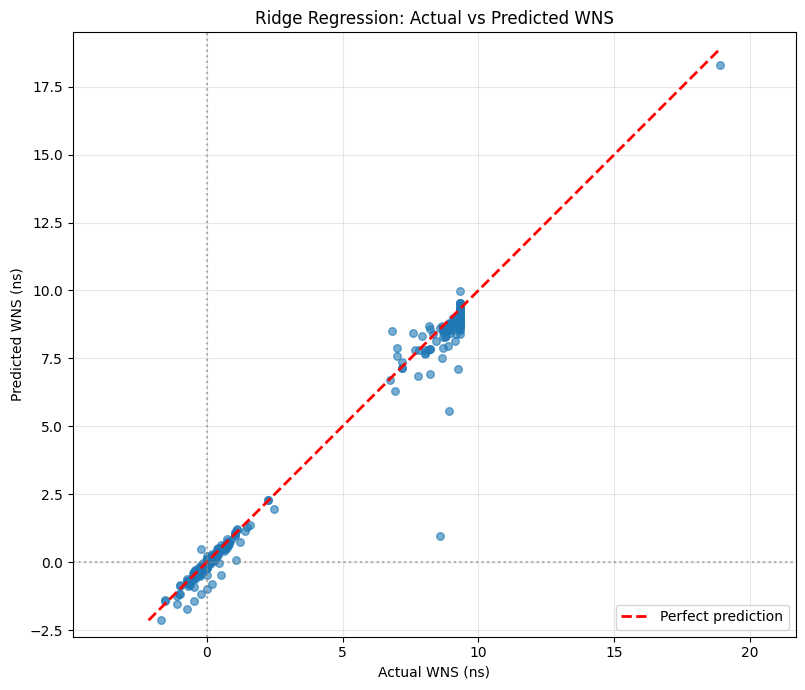

In [11]:

import numpy as np
import matplotlib.pyplot as plt

# Ensure Ridge is trained at the best alpha
ridge.set_params(model__alpha=best_alpha)
ridge.fit(X_train, y_train)

actual = y_val.to_numpy()
predicted = ridge.predict(X_val)

plt.figure(figsize=(8, 7))

plt.scatter(actual, predicted, alpha=0.6, s=30)

limits = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

# Perfect prediction line
plt.plot(limits, limits, 'r--',
         linewidth=2, label="Perfect prediction")

plt.axhline(0, color='gray', linestyle=':', alpha=0.6)
plt.axvline(0, color='gray', linestyle=':', alpha=0.6)

plt.xlabel("Actual WNS (ns)")
plt.ylabel("Predicted WNS (ns)")
plt.title("Ridge Regression: Actual vs Predicted WNS")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()


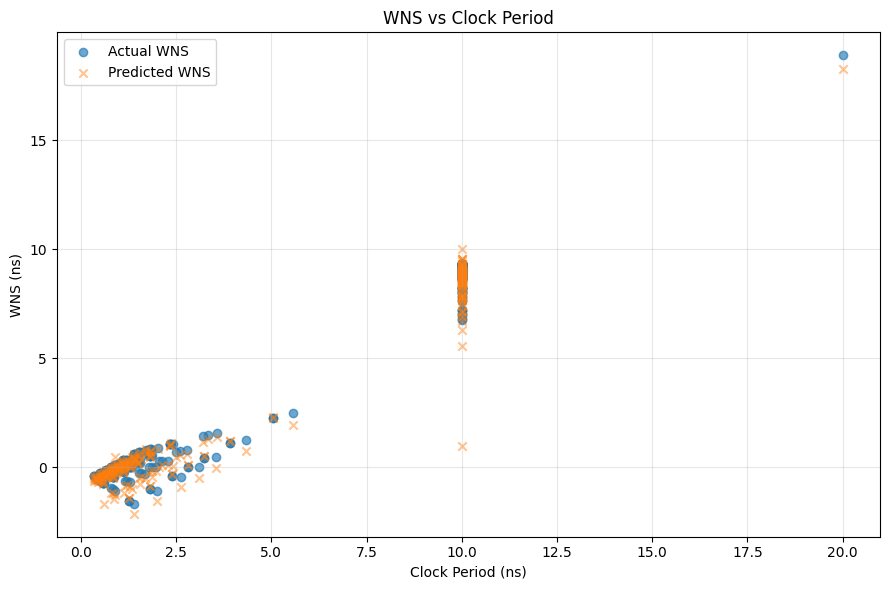

In [12]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X_val["clock_period_ns"],
    actual,
    alpha=0.65,
    label="Actual WNS"
)

plt.scatter(
    X_val["clock_period_ns"],
    predicted,
    alpha=0.45,
    marker="x",
    label="Predicted WNS"
)

plt.xlabel("Clock Period (ns)")
plt.ylabel("WNS (ns)")
plt.title("WNS vs Clock Period")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score

actual = y_val.to_numpy()
predicted = ridge.predict(X_val)
clock = X_val["clock_period_ns"].to_numpy()

regimes = {
    "T < 3 ns": clock < 3,
    "3 <= T < 7 ns": (clock >= 3) & (clock < 7),
    "T = 10 ns": np.isclose(clock, 10),
    "T > 10 ns": clock > 10
}

rows = []

for name, mask in regimes.items():
    if mask.sum() == 0:
        continue

    rows.append({
        "Clock regime": name,
        "Samples": mask.sum(),
        "MAE (ns)": mean_absolute_error(
            actual[mask], predicted[mask]
        ),
        "Mean bias (ns)": np.mean(
            predicted[mask] - actual[mask]
        ),
        "R2": (
            r2_score(actual[mask], predicted[mask])
            if mask.sum() >= 2 else np.nan
        )
    })

display(pd.DataFrame(rows).round(4))


,Clock regime,Samples,MAE (ns),Mean bias (ns),R2
0,T < 3 ns,158,0.1404,-0.0979,0.7721
1,3 <= T < 7 ns,13,0.2360,-0.1751,0.8378
2,T = 10 ns,122,0.4821,-0.3627,-0.9250
3,T > 10 ns,1,0.6100,-0.6100,NaN


10 ns observations: 122


,design,architecture,clock_period_ns,actual_wns,predicted_wns,residual,abs_error
48,v3__control__arbiter_round_robin__w64,arbiter_round_robin,10.0,8.5882,0.9489,-7.6393,7.6393
16,control__arbiter_round_robin__w32,arbiter_round_robin,10.0,8.9227,5.5626,-3.3601,3.3601
15,control__arbiter_round_robin__w16,arbiter_round_robin,10.0,9.2321,7.1037,-2.1284,2.1284
43,v3__arithmetic__mul_behavioral__w64,mul_behavioral,10.0,6.8129,8.5154,1.7025,1.7025
38,v3__arithmetic__compare_priority__w64,compare_priority,10.0,8.2024,6.9380,-1.2644,1.2644
254,v5__sequential__timer__w32__v5_baseline,timer,10.0,8.6590,7.5045,-1.1545,1.1545
75,v3__data_movement__rotate_barrel__w64,rotate_barrel,10.0,9.1218,8.1439,-0.9779,0.9779
9,arithmetic__compare_priority__w16,compare_priority,10.0,9.3185,8.3874,-0.9311,0.9311
100,v3__system_level__stream_valid_pipeline__w64,stream_valid_pipeline,10.0,7.7882,6.8688,-0.9194,0.9194
10,arithmetic__compare_priority__w32,compare_priority,10.0,8.8761,7.9733,-0.9028,0.9028


MAE including all: 0.48206758554805335
MAE excluding worst 1: 0.42291670351616706
MAE excluding worst 5: 0.36510632895786677


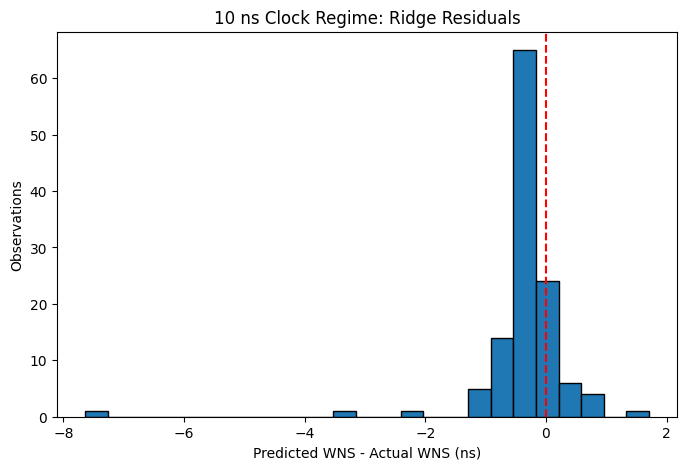

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ridge.set_params(model__alpha=best_alpha)
ridge.fit(X_train, y_train)

actual = y_val.to_numpy()
predicted = ridge.predict(X_val)

df = val[[
    "design", "architecture", "clock_period_ns"
]].copy()

df["actual_wns"] = actual
df["predicted_wns"] = predicted
df["residual"] = predicted - actual
df["abs_error"] = np.abs(df["residual"])

clock10 = df[np.isclose(df["clock_period_ns"], 10)]

print("10 ns observations:", len(clock10))

display(
    clock10.sort_values(
        "abs_error", ascending=False
    ).head(15).round(4)
)

# How much does the worst outlier contribute?
errors = clock10["abs_error"].sort_values(ascending=False)

print("MAE including all:", errors.mean())
print("MAE excluding worst 1:", errors.iloc[1:].mean())
print("MAE excluding worst 5:", errors.iloc[5:].mean())

# Residual distribution
plt.figure(figsize=(8, 5))
plt.hist(clock10["residual"], bins=25, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Predicted WNS - Actual WNS (ns)")
plt.ylabel("Observations")
plt.title("10 ns Clock Regime: Ridge Residuals")
plt.show()


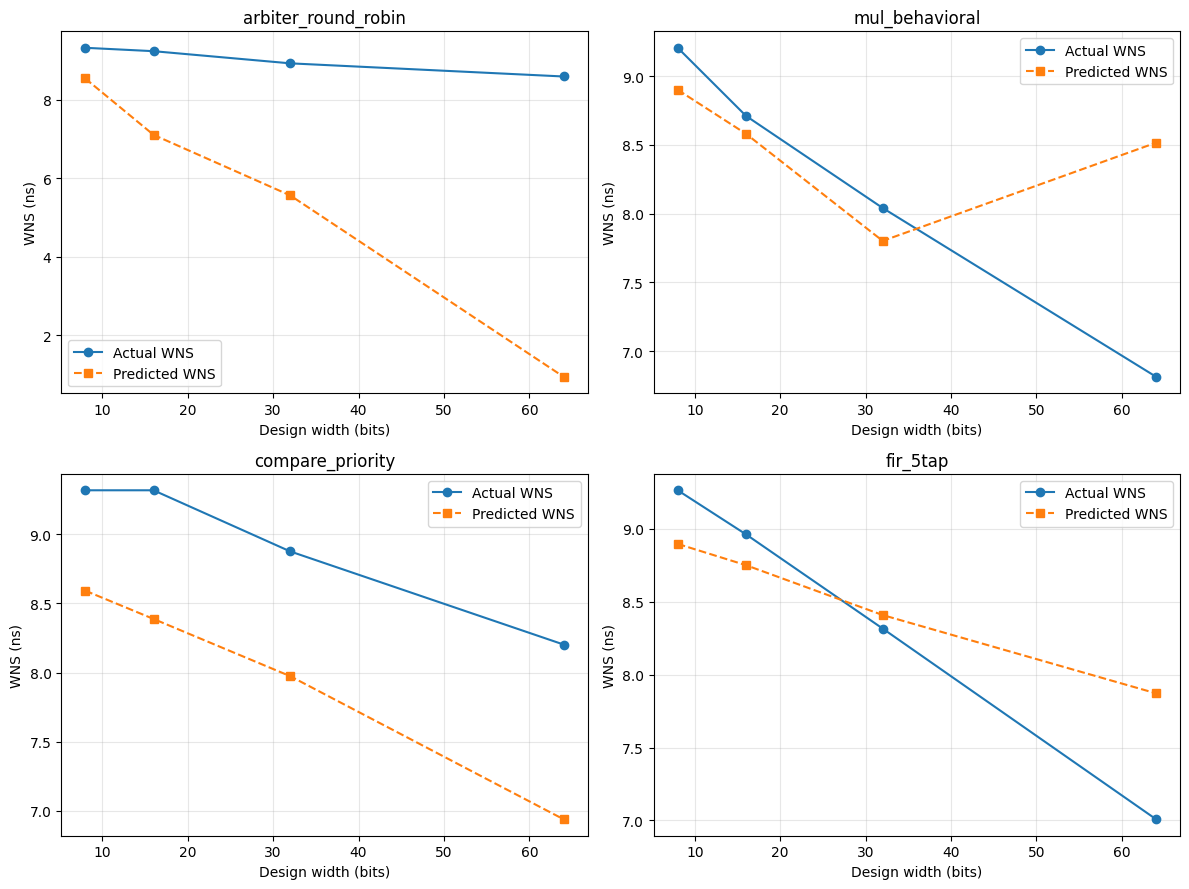

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ridge.set_params(model__alpha=best_alpha)
ridge.fit(X_train, y_train)

diagnostics = val[
    ["design", "architecture", "clock_period_ns"]
].copy()

diagnostics["width"] = X_val["design_width_bits"].to_numpy()
diagnostics["actual_wns"] = y_val.to_numpy()
diagnostics["predicted_wns"] = ridge.predict(X_val)
diagnostics["error"] = (
    diagnostics["predicted_wns"]
    - diagnostics["actual_wns"]
)

architectures = [
    "arbiter_round_robin",
    "mul_behavioral",
    "compare_priority",
    "fir_5tap"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, arch in zip(axes.flat, architectures):
    subset = diagnostics[
        (diagnostics["architecture"] == arch)
        & np.isclose(diagnostics["clock_period_ns"], 10)
    ].sort_values("width")

    if subset.empty:
        ax.set_title(f"{arch}: no observations")
        continue

    ax.plot(
        subset["width"],
        subset["actual_wns"],
        "o-",
        label="Actual WNS"
    )
    ax.plot(
        subset["width"],
        subset["predicted_wns"],
        "s--",
        label="Predicted WNS"
    )

    ax.set_title(arch)
    ax.set_xlabel("Design width (bits)")
    ax.set_ylabel("WNS (ns)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


RANDOM FOREST


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

rf = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True,
        keep_empty_features=True
    )),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)

rf_train_pred = rf.predict(X_train)
rf_val_pred = rf.predict(X_val)

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

print("RANDOM FOREST — TRAINING")
print(regression_metrics(y_train, rf_train_pred))

print("\nRANDOM FOREST — VALIDATION")
print(regression_metrics(y_val, rf_val_pred))


RANDOM FOREST — TRAINING
{'MAE': 0.10266536809406605, 'RMSE': np.float64(0.5319220946128949), 'R2': 0.9807247950649225}

RANDOM FOREST — VALIDATION
{'MAE': 0.3134505222333857, 'RMSE': np.float64(0.6146409043270449), 'R2': 0.9810956472069088}


In [17]:

from sklearn.base import clone

depths = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]

rf_results = []
rf_models = {}

for depth in depths:
    model = clone(rf)
    model.set_params(model__max_depth=depth)

    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)

    rf_results.append({
        "max_depth": depth,
        "Train MAE": mean_absolute_error(y_train, pred_train),
        "Validation MAE": mean_absolute_error(y_val, pred_val),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, pred_val)
        ),
        "Validation R2": r2_score(y_val, pred_val)
    })

    rf_models[str(depth)] = model

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df.round(4))

best_row = rf_results_df.loc[
    rf_results_df["Validation MAE"].idxmin()
]

best_depth = best_row["max_depth"]

print("\nBest depth:", best_depth)
print("Best validation MAE:", best_row["Validation MAE"])


,max_depth,Train MAE,Validation MAE,Validation RMSE,Validation R2
0,2.0,0.3693,0.4406,0.7621,0.9709
1,3.0,0.3075,0.3674,0.6449,0.9792
2,4.0,0.2458,0.3705,0.6393,0.9796
3,5.0,0.2059,0.3648,0.6410,0.9794
4,6.0,0.1693,0.3457,0.6284,0.9802
5,8.0,0.1221,0.3202,0.6149,0.9811
6,10.0,0.1027,0.3135,0.6146,0.9811
7,12.0,0.0975,0.3117,0.6135,0.9812
8,15.0,0.0964,0.3117,0.6142,0.9811
9,20.0,0.0964,0.3115,0.6136,0.9812



Best depth: nan
Best validation MAE: 0.31152227554472345


In [18]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd

results = []

for leaf in [1, 2, 3, 5, 10]:
    for max_features in [0.5, 0.75, 1.0]:

        model = clone(rf)
        model.set_params(
            model__max_depth=12,
            model__min_samples_leaf=leaf,
            model__max_features=max_features,
            model__n_estimators=300
        )

        model.fit(X_train, y_train)

        train_mae = mean_absolute_error(
            y_train, model.predict(X_train)
        )

        val_mae = mean_absolute_error(
            y_val, model.predict(X_val)
        )

        results.append({
            "min_samples_leaf": leaf,
            "max_features": max_features,
            "Train MAE": train_mae,
            "Validation MAE": val_mae
        })

rf_tuning = pd.DataFrame(results)

display(
    rf_tuning.sort_values("Validation MAE").round(4)
)


,min_samples_leaf,max_features,Train MAE,Validation MAE
2,1,1.00,0.0485,0.1729
1,1,0.75,0.0534,0.1894
5,2,1.00,0.0677,0.2074
4,2,0.75,0.0733,0.2259
0,1,0.50,0.0708,0.2265
3,2,0.50,0.0985,0.2827
13,10,0.75,0.1904,0.2890
14,10,1.00,0.1857,0.2969
7,3,0.75,0.1020,0.3003
8,3,1.00,0.0975,0.3117


XGBoost


In [19]:

!pip -q install xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("XGBoost version:", xgb.__version__)

# Preserve the same features and architecture-disjoint split
xgb_model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    reg_alpha=0.0,
    objective="reg:squarederror",
    eval_metric="mae",
    early_stopping_rounds=50,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

print("Best boosting iteration:", xgb_model.best_iteration)
print("Best validation MAE:", xgb_model.best_score)


XGBoost version: 3.4.1
Best boosting iteration: 183
Best validation MAE: 0.36262251127694994


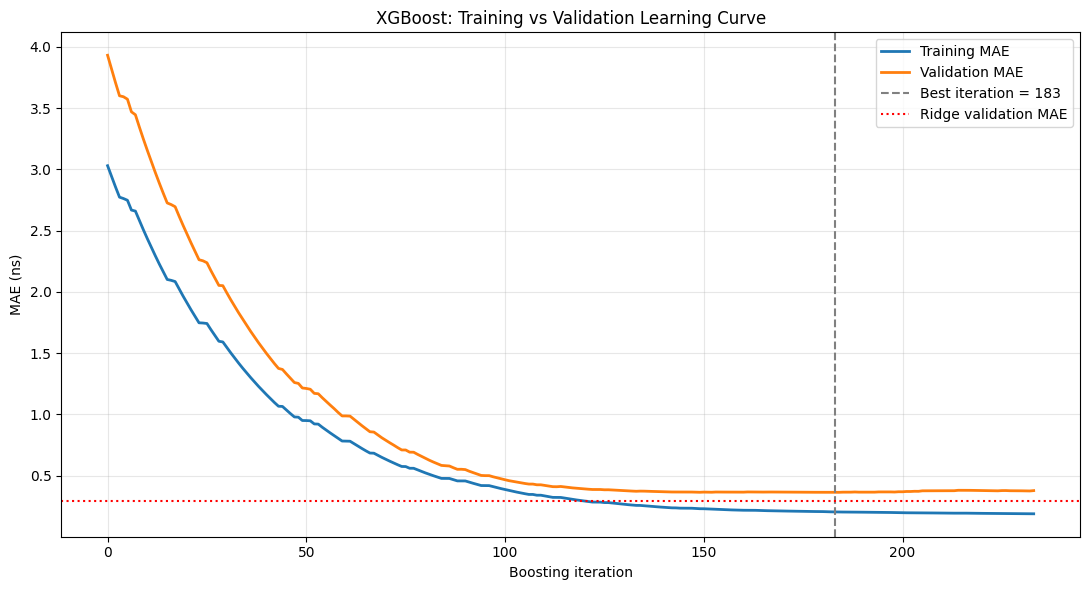

In [20]:

history = xgb_model.evals_result()

train_mae = history["validation_0"]["mae"]
val_mae = history["validation_1"]["mae"]

best_iteration = xgb_model.best_iteration

plt.figure(figsize=(11, 6))

plt.plot(
    train_mae,
    label="Training MAE",
    linewidth=2
)

plt.plot(
    val_mae,
    label="Validation MAE",
    linewidth=2
)

plt.axvline(
    best_iteration,
    color="gray",
    linestyle="--",
    label=f"Best iteration = {best_iteration}"
)

plt.axhline(
    0.2879869684901385,
    color="red",
    linestyle=":",
    label="Ridge validation MAE"
)

plt.xlabel("Boosting iteration")
plt.ylabel("MAE (ns)")
plt.title("XGBoost: Training vs Validation Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(y_true, y_pred):
    actual = np.asarray(y_true)
    predicted = np.asarray(y_pred)

    actual_violation = (actual < 0).astype(int)
    predicted_violation = (predicted < 0).astype(int)

    cm = confusion_matrix(
        actual_violation,
        predicted_violation,
        labels=[0, 1]
    )

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Mean Bias": np.mean(predicted - actual),
        "Violation Precision": precision_score(
            actual_violation, predicted_violation,
            zero_division=0
        ),
        "Violation Recall": recall_score(
            actual_violation, predicted_violation,
            zero_division=0
        ),
        "Violation F1": f1_score(
            actual_violation, predicted_violation,
            zero_division=0
        ),
        "False Negatives": int(cm[1, 0]),
        "False Positives": int(cm[0, 1])
    }

# Evaluate XGBoost
xgb_train_pred = xgb_model.predict(X_train)
xgb_val_pred = xgb_model.predict(X_val)

print("XGBOOST TRAINING")
print(evaluate_model(y_train, xgb_train_pred))

print("\nXGBOOST VALIDATION")
print(evaluate_model(y_val, xgb_val_pred))

print("\nVIOLATION CLASSIFICATION REPORT")
print(classification_report(
    (np.asarray(y_val) < 0).astype(int),
    (xgb_val_pred < 0).astype(int),
    target_names=["Timing met", "Violation"],
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(
    np.asarray(y_val) < 0,
    xgb_val_pred < 0
))

# Compare clock regimes
clock = X_val["clock_period_ns"].to_numpy()
actual = y_val.to_numpy()

regimes = {
    "T < 3 ns": clock < 3,
    "3 <= T < 7 ns": (clock >= 3) & (clock < 7),
    "T = 10 ns": np.isclose(clock, 10),
    "T > 10 ns": clock > 10
}

rows = []

for name, mask in regimes.items():
    if not mask.any():
        continue

    rows.append({
        "Clock regime": name,
        "Samples": int(mask.sum()),
        "XGBoost MAE": mean_absolute_error(
            actual[mask], xgb_val_pred[mask]
        ),
        "XGBoost Bias": np.mean(
            xgb_val_pred[mask] - actual[mask]
        ),
        "XGBoost R2": (
            r2_score(actual[mask], xgb_val_pred[mask])
            if mask.sum() >= 2 else np.nan
        )
    })

display(pd.DataFrame(rows).round(4))


XGBOOST TRAINING
{'MAE': 0.20310676328702132, 'RMSE': np.float64(0.632518241524405), 'R2': 0.972744820054099, 'Mean Bias': np.float64(0.0022693510272309065), 'Violation Precision': 0.869215291750503, 'Violation Recall': 0.9452954048140044, 'Violation F1': 0.9056603773584906, 'False Negatives': 25, 'False Positives': 65}

XGBOOST VALIDATION
{'MAE': 0.36262251318740546, 'RMSE': np.float64(0.7444056505394793), 'R2': 0.9722707439960991, 'Mean Bias': np.float64(0.1932495246781099), 'Violation Precision': 0.9482758620689655, 'Violation Recall': 0.7534246575342466, 'Violation F1': 0.8396946564885496, 'False Negatives': 18, 'False Positives': 3}

VIOLATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Timing met       0.92      0.99      0.95       221
   Violation       0.95      0.75      0.84        73

    accuracy                           0.93       294
   macro avg       0.94      0.87      0.90       294
weighted avg       0.93      0.93      0.93      

,Clock regime,Samples,XGBoost MAE,XGBoost Bias,XGBoost R2
0,T < 3 ns,158,0.2491,0.1957,0.5193
1,3 <= T < 7 ns,13,0.5812,0.4572,0.1692
2,T = 10 ns,122,0.4063,0.2467,0.3580
3,T > 10 ns,1,10.1396,-10.1396,NaN


In [23]:

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Clock periods
T_train = X_train["clock_period_ns"].to_numpy()
T_val = X_val["clock_period_ns"].to_numpy()

# Effective timing quantity
D_train = T_train - y_train.to_numpy()
D_val = T_val - y_val.to_numpy()

# Avoid giving the model the clock period initially.
# This tests whether structural features can predict
# the effective timing quantity independently.
structural_features = [
    c for c in X_train.columns
    if c != "clock_period_ns"
]

X_train_struct = X_train[structural_features]
X_val_struct = X_val[structural_features]

delay_xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    objective="reg:squarederror",
    eval_metric="mae",
    early_stopping_rounds=50,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

delay_xgb.fit(
    X_train_struct,
    D_train,
    eval_set=[
        (X_train_struct, D_train),
        (X_val_struct, D_val)
    ],
    verbose=False
)

# Reconstruct WNS
D_pred_train = delay_xgb.predict(X_train_struct)
D_pred_val = delay_xgb.predict(X_val_struct)

wns_pred_train = T_train - D_pred_train
wns_pred_val = T_val - D_pred_val

print("Best iteration:", delay_xgb.best_iteration)

print("\nPHYSICS-INFORMED XGBOOST")
print("Training MAE:",
      mean_absolute_error(y_train, wns_pred_train))
print("Validation MAE:",
      mean_absolute_error(y_val, wns_pred_val))
print("Validation RMSE:",
      np.sqrt(mean_squared_error(y_val, wns_pred_val)))
print("Validation R2:",
      r2_score(y_val, wns_pred_val))

print("\nViolation classification:")
print(evaluate_model(y_val, wns_pred_val))

# Compare by clock regime
clock = T_val
actual = y_val.to_numpy()

regimes = {
    "T < 3 ns": clock < 3,
    "3 <= T < 7 ns": (clock >= 3) & (clock < 7),
    "T = 10 ns": np.isclose(clock, 10),
    "T > 10 ns": clock > 10
}

rows = []

for name, mask in regimes.items():
    if mask.sum() == 0:
        continue

    rows.append({
        "Regime": name,
        "Samples": int(mask.sum()),
        "Original XGB MAE": mean_absolute_error(
            actual[mask],
            xgb_val_pred[mask]
        ),
        "Delay-based XGB MAE": mean_absolute_error(
            actual[mask],
            wns_pred_val[mask]
        )
    })

display(pd.DataFrame(rows).round(4))


Best iteration: 210

PHYSICS-INFORMED XGBOOST
Training MAE: 0.12598349262152436
Validation MAE: 0.2341233453977676
Validation RMSE: 0.30852565074831306
Validation R2: 0.9952367711341377

Violation classification:
{'MAE': 0.2341233453977676, 'RMSE': np.float64(0.30852565074831306), 'R2': 0.9952367711341377, 'Mean Bias': np.float64(0.04509591142693339), 'Violation Precision': 0.810126582278481, 'Violation Recall': 0.8767123287671232, 'Violation F1': 0.8421052631578947, 'False Negatives': 9, 'False Positives': 15}


,Regime,Samples,Original XGB MAE,Delay-based XGB MAE
0,T < 3 ns,158,0.2491,0.1961
1,3 <= T < 7 ns,13,0.5812,0.6207
2,T = 10 ns,122,0.4063,0.2407
3,T > 10 ns,1,10.1396,0.4143


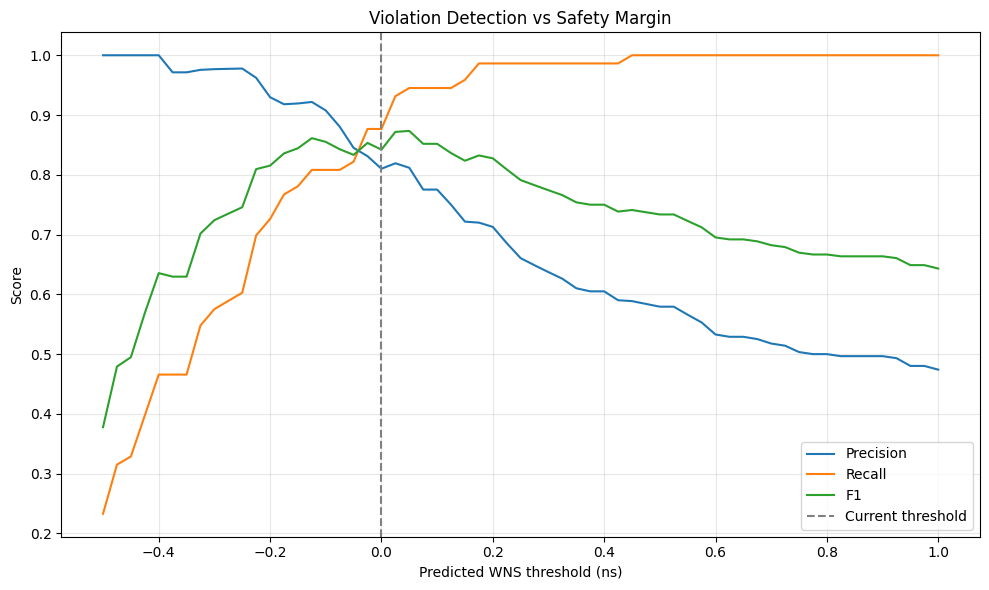

,Threshold (ns),Precision,Recall,F1,False Negatives,False Positives
27,0.175,0.7200,0.9863,0.8324,1,28
28,0.200,0.7129,0.9863,0.8276,1,29
29,0.225,0.6857,0.9863,0.8090,1,33
30,0.250,0.6606,0.9863,0.7912,1,37
31,0.275,0.6486,0.9863,0.7826,1,39
32,0.300,0.6372,0.9863,0.7742,1,41
33,0.325,0.6261,0.9863,0.7660,1,43
34,0.350,0.6102,0.9863,0.7539,1,46
35,0.375,0.6050,0.9863,0.7500,1,47
36,0.400,0.6050,0.9863,0.7500,1,47


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

actual_violation = (y_val.to_numpy() < 0).astype(int)
predicted_wns = wns_pred_val

thresholds = np.arange(-0.5, 1.01, 0.025)

results = []

for threshold in thresholds:
    predicted_violation = (
        predicted_wns < threshold
    ).astype(int)

    cm = confusion_matrix(
        actual_violation,
        predicted_violation,
        labels=[0, 1]
    )

    results.append({
        "Threshold (ns)": threshold,
        "Precision": precision_score(
            actual_violation,
            predicted_violation,
            zero_division=0
        ),
        "Recall": recall_score(
            actual_violation,
            predicted_violation,
            zero_division=0
        ),
        "F1": f1_score(
            actual_violation,
            predicted_violation,
            zero_division=0
        ),
        "False Negatives": cm[1, 0],
        "False Positives": cm[0, 1]
    })

threshold_df = pd.DataFrame(results)

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold (ns)"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold (ns)"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold (ns)"],
    threshold_df["F1"],
    label="F1"
)

plt.axvline(0, color="gray", linestyle="--",
            label="Current threshold")

plt.xlabel("Predicted WNS threshold (ns)")
plt.ylabel("Score")
plt.title("Violation Detection vs Safety Margin")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(
    threshold_df.loc[
        threshold_df["False Negatives"] <= 1
    ].sort_values(
        "False Positives"
    ).head(10).round(4)
)


Validation samples: 294
MAE: 0.2341233453977676
RMSE: 0.30852565074831306
R2: 0.9952367711341377

Classification threshold: 0.175 ns
Confusion matrix:
[[193  28]
 [  1  72]]


,design,architecture,clock_period_ns,actual_wns,predicted_wns,signed_error_ns,absolute_error_ns,actual_violation,predicted_violation,classification
36,v3__arithmetic__carry_save_3to2__w64,carry_save_3to2,10.0000,6.7586,7.8497,1.0911,1.0911,False,False,TN
43,v3__arithmetic__mul_behavioral__w64,mul_behavioral,10.0000,6.8129,5.8076,-1.0053,1.0053,False,False,TN
157,v4__add_sub__w64__s1__v4_p06,add_sub,5.5566,2.4696,3.3778,0.9082,0.9082,False,False,TN
154,v4__add_sub__w64__s1__v4_p03,add_sub,3.0870,0.0000,0.9082,0.9082,0.9082,False,False,TN
153,v4__add_sub__w64__s1__v4_p02,add_sub,2.6239,-0.4631,0.4451,0.9082,0.9082,True,False,FN
152,v4__add_sub__w64__s1__v4_p01,add_sub,2.0065,-1.0805,-0.1723,0.9082,0.9082,True,True,TP
151,v4__add_sub__w64__s1__v4_p00,add_sub,1.3891,-1.6979,-0.7897,0.9082,0.9082,True,True,TP
155,v4__add_sub__w64__s1__v4_p04,add_sub,3.5500,0.4630,1.3712,0.9082,0.9082,False,False,TN
156,v4__add_sub__w64__s1__v4_p05,add_sub,4.3218,1.2348,2.1430,0.9082,0.9082,False,False,TN
150,v4__add_sub__w64__s1__v4_baseline,add_sub,10.0000,6.9130,7.8212,0.9082,0.9082,False,False,TN


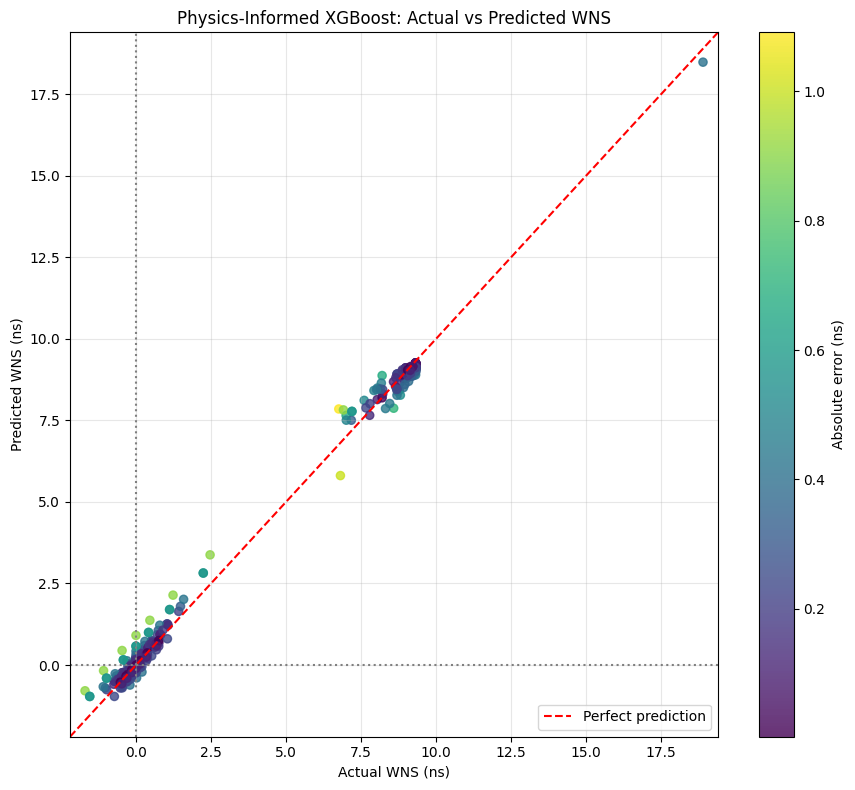


PREDICTION ACCURACY BY TOLERANCE
Within ±0.05 ns: 6.80%
Within ±0.10 ns: 24.49%
Within ±0.20 ns: 51.02%
Within ±0.30 ns: 75.17%
Within ±0.50 ns: 89.46%
Within ±1.00 ns: 99.32%


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix
)

# Raw WNS prediction — no classification threshold applied
actual = y_val.to_numpy()
predicted = (
    X_val["clock_period_ns"].to_numpy()
    - delay_xgb.predict(X_val_struct)
)

threshold = 0.175

# Create a NEW DataFrame with an unambiguous name
prediction_df = val[
    ["design", "architecture", "clock_period_ns"]
].copy().reset_index(drop=True)

prediction_df["actual_wns"] = actual
prediction_df["predicted_wns"] = predicted
prediction_df["signed_error_ns"] = predicted - actual
prediction_df["absolute_error_ns"] = np.abs(predicted - actual)

# Threshold is used ONLY for classification
prediction_df["actual_violation"] = actual < 0
prediction_df["predicted_violation"] = predicted < threshold

prediction_df["classification"] = np.select(
    [
        prediction_df["actual_violation"] &
        prediction_df["predicted_violation"],

        ~prediction_df["actual_violation"] &
        ~prediction_df["predicted_violation"],

        ~prediction_df["actual_violation"] &
        prediction_df["predicted_violation"],

        prediction_df["actual_violation"] &
        ~prediction_df["predicted_violation"]
    ],
    ["TP", "TN", "FP", "FN"],
    default="Unknown"
)

print("Validation samples:", len(prediction_df))
print("MAE:", mean_absolute_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
print("R2:", r2_score(actual, predicted))

print("\nClassification threshold:", threshold, "ns")
print("Confusion matrix:")
print(confusion_matrix(
    prediction_df["actual_violation"],
    prediction_df["predicted_violation"],
    labels=[False, True]
))

display(
    prediction_df.sort_values(
        "absolute_error_ns", ascending=False
    ).head(25).round(4)
)

# Actual vs predicted plot
plt.figure(figsize=(9, 8))

scatter = plt.scatter(
    actual,
    predicted,
    c=np.abs(predicted - actual),
    cmap="viridis",
    alpha=0.8,
    s=35
)

limits = [
    min(actual.min(), predicted.min()) - 0.5,
    max(actual.max(), predicted.max()) + 0.5
]

plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.axhline(0, color="gray", linestyle=":")
plt.axvline(0, color="gray", linestyle=":")

plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual WNS (ns)")
plt.ylabel("Predicted WNS (ns)")
plt.title("Physics-Informed XGBoost: Actual vs Predicted WNS")
plt.colorbar(scatter, label="Absolute error (ns)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Error tolerance analysis
print("\nPREDICTION ACCURACY BY TOLERANCE")

for tolerance in [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]:
    within = np.mean(
        prediction_df["absolute_error_ns"] <= tolerance
    ) * 100

    print(f"Within ±{tolerance:.2f} ns: {within:.2f}%")



Total timing observations: 294
Unique circuits: 122

Observation-weighted MAE:
0.2341233453977676

Circuit-weighted MAE:
0.24218729780384762

Worst 20 unique circuits:


,circuit_id,architecture,observations,MAE,max_error,mean_bias
51,688f145255358d010c286d1abb8e6d98404aa6e5098857...,carry_save_3to2,1,1.0911,1.0911,1.0911
89,b3fcddb930a3a61cb6a404b2735dc814b6d84e600920c4...,mul_behavioral,1,1.0053,1.0053,-1.0053
28,3207a37f372b5fcd4d64b3337ff352f9a46e2e4e8763dc...,add_sub,8,0.9082,0.9082,0.9082
106,e1df193d78d1d3961dba31322616daed6d172949094a91...,arbiter_round_robin,1,0.7153,0.7153,-0.7153
88,b17180df81f344d68539d51a64bbff4f422b7c82b3edda...,compare_priority,1,0.6721,0.6721,0.6721
27,2f7106a3c58440d396aeb261e4885d1e02b043ee26e35a...,saturating_add,1,0.6485,0.6485,0.6485
1,04ba258700549a68b41fb642ea2183c0aa5ddd98092df7...,add_sub,8,0.5784,0.5784,0.5784
40,50ebac6b30d6af15f276d997a419b40195933e2e3c6f7b...,add_sub,8,0.5784,0.5784,0.5784
76,9f041e84b8a77ff49c967da55f7fab72fc2674f2664931...,fir_2tap,1,0.5376,0.5376,-0.5376
90,bc4183bc9bb8ed111972997675e1a76e26fb280463d640...,add_prefix_brent_kung,1,0.5085,0.5085,0.5085


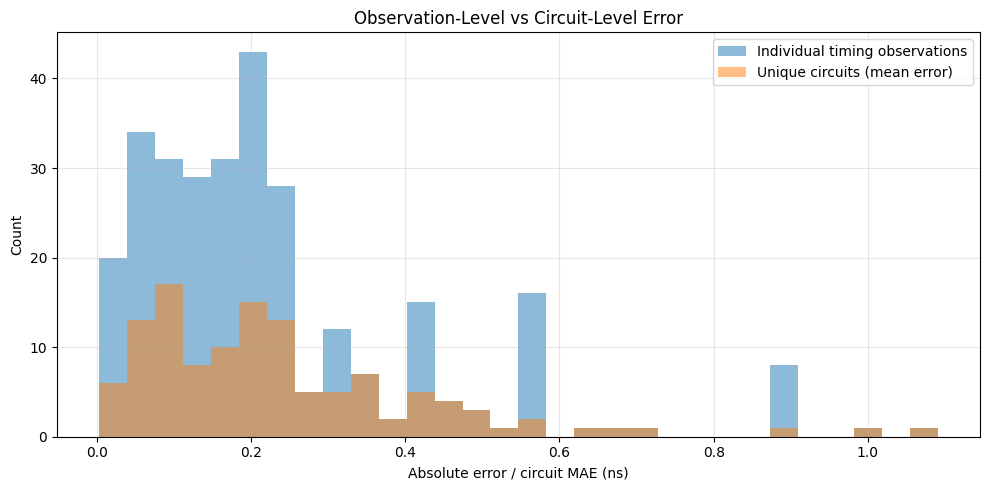

In [27]:

# Use the existing prediction_df

design_eval = prediction_df.copy()

# Prefer RTL hash as the circuit identifier
if "rtl_sha256" in val.columns:
    design_eval["circuit_id"] = val["rtl_sha256"].to_numpy()
else:
    design_eval["circuit_id"] = val["design"].to_numpy()

# Each circuit contributes equally, regardless of
# how many clock-period observations it has.
per_circuit = (
    design_eval.groupby("circuit_id")
    .agg(
        architecture=("architecture", "first"),
        observations=("absolute_error_ns", "size"),
        MAE=("absolute_error_ns", "mean"),
        max_error=("absolute_error_ns", "max"),
        mean_bias=("signed_error_ns", "mean")
    )
    .reset_index()
)

print("Total timing observations:", len(design_eval))
print("Unique circuits:", len(per_circuit))

print("\nObservation-weighted MAE:")
print(design_eval["absolute_error_ns"].mean())

print("\nCircuit-weighted MAE:")
print(per_circuit["MAE"].mean())

print("\nWorst 20 unique circuits:")
display(
    per_circuit.sort_values(
        "MAE", ascending=False
    ).head(20).round(4)
)

# Compare error distributions
plt.figure(figsize=(10, 5))

plt.hist(
    design_eval["absolute_error_ns"],
    bins=30,
    alpha=0.5,
    label="Individual timing observations"
)

plt.hist(
    per_circuit["MAE"],
    bins=30,
    alpha=0.5,
    label="Unique circuits (mean error)"
)

plt.xlabel("Absolute error / circuit MAE (ns)")
plt.ylabel("Count")
plt.title("Observation-Level vs Circuit-Level Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the same transformed target for every model
T_train = X_train["clock_period_ns"].to_numpy()
T_val = X_val["clock_period_ns"].to_numpy()

D_train = T_train - y_train.to_numpy()
D_val = T_val - y_val.to_numpy()

feature_cols = [
    col for col in X_train.columns
    if col != "clock_period_ns"
]

Xtr = X_train[feature_cols]
Xva = X_val[feature_cols]

# Model 1: Delay-based Ridge
delay_ridge = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True,
        keep_empty_features=True
    )),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=36.2096))
])

# Model 2: Delay-based Random Forest
delay_rf = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True,
        keep_empty_features=True
    )),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    "Delay-based Ridge": delay_ridge,
    "Delay-based Random Forest": delay_rf
}

rows = []

for name, model in models.items():
    model.fit(Xtr, D_train)

    train_pred = T_train - model.predict(Xtr)
    val_pred = T_val - model.predict(Xva)

    rows.append({
        "Model": name,
        "Train MAE": mean_absolute_error(
            y_train, train_pred
        ),
        "Validation MAE": mean_absolute_error(
            y_val, val_pred
        ),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, val_pred)
        ),
        "Validation R2": r2_score(
            y_val, val_pred
        )
    })

# Include the already-trained physics-informed XGBoost
xgb_train_pred = (
    T_train - delay_xgb.predict(X_train_struct)
)

xgb_val_pred = (
    T_val - delay_xgb.predict(X_val_struct)
)

rows.append({
    "Model": "Delay-based XGBoost",
    "Train MAE": mean_absolute_error(
        y_train, xgb_train_pred
    ),
    "Validation MAE": mean_absolute_error(
        y_val, xgb_val_pred
    ),
    "Validation RMSE": np.sqrt(
        mean_squared_error(y_val, xgb_val_pred)
    ),
    "Validation R2": r2_score(
        y_val, xgb_val_pred
    )
})

comparison_df = pd.DataFrame(rows).sort_values(
    "Validation MAE"
)

display(comparison_df.round(4))


,Model,Train MAE,Validation MAE,Validation RMSE,Validation R2
1,Delay-based Random Forest,0.0482,0.2232,0.3419,0.9941
2,Delay-based XGBoost,0.1260,0.2341,0.3085,0.9952
0,Delay-based Ridge,0.2287,0.2832,0.6517,0.9787


In [30]:

# Create test features using EXACTLY the same columns
# as the training data.

X_test = test[feature_columns].copy()
y_test = test["worst_slack_ns"].copy()

# Prepare features for both trained models
X_test_rf = X_test[Xva.columns].copy()
X_test_xgb = X_test[X_val_struct.columns].copy()

print("Test observations:", len(X_test))
print("Random Forest features:", X_test_rf.shape)
print("XGBoost features:", X_test_xgb.shape)

# Verify that feature ordering matches training
assert list(X_test_rf.columns) == list(Xva.columns)
assert list(X_test_xgb.columns) == list(X_val_struct.columns)

print("Test data prepared successfully.")


Test observations: 289
Random Forest features: (289, 46)
XGBoost features: (289, 46)
Test data prepared successfully.


FINAL TEST REGRESSION RESULTS


,Model,MAE (ns),RMSE (ns),R2,Mean Bias (ns),Median AE (ns),95th Percentile AE (ns),Maximum AE (ns),Within ±0.2 ns (%),Within ±0.5 ns (%)
0,Random Forest,0.2480,0.8715,0.9688,-0.0440,0.1342,0.4372,9.6680,69.5502,96.1938
1,XGBoost,0.3385,0.9776,0.9608,-0.0939,0.2389,0.4759,11.1752,36.6782,95.5017



FINAL TEST VIOLATION DETECTION


,Model,Threshold (ns),Precision,Recall,F1,True Positives,True Negatives,False Positives,False Negatives
0,Random Forest,0.000,0.8515,0.9348,0.8912,86,182,15,6
1,Random Forest,0.175,0.7627,0.9783,0.8571,90,169,28,2
2,XGBoost,0.000,0.8095,0.9239,0.8629,85,177,20,7
3,XGBoost,0.175,0.7627,0.9783,0.8571,90,169,28,2


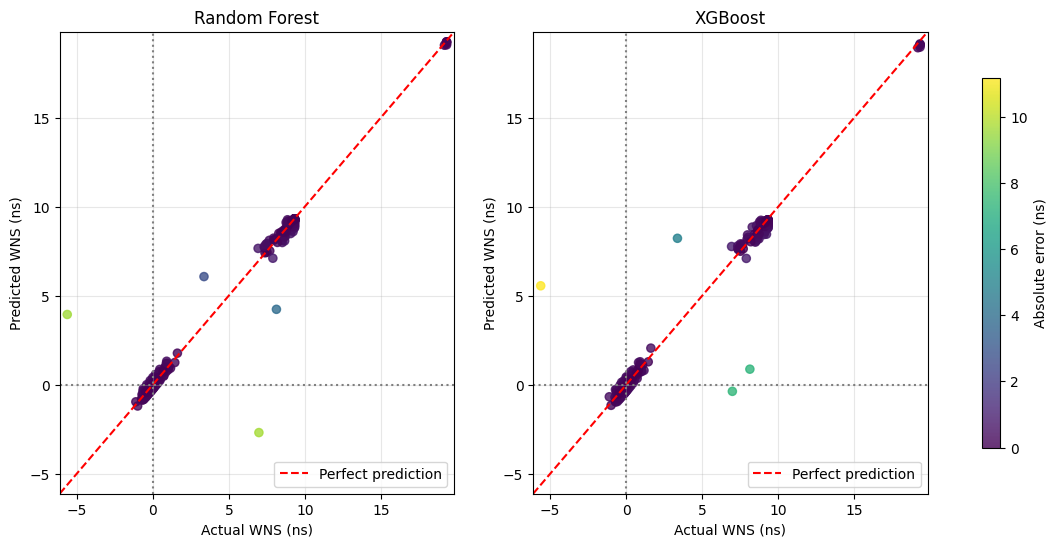


NUMBER OF TEST OBSERVATIONS WON


,count
better_model,
Random Forest,203
XGBoost,86



20 MOST DIFFICULT TEST OBSERVATIONS


,design,architecture,clock_period_ns,actual_wns,rf_predicted_wns,xgb_predicted_wns,rf_absolute_error,xgb_absolute_error,better_model,worst_error
148,v3__arithmetic__mul_shift_add__w64,mul_shift_add,10.0,-5.6227,3.9417,5.5525,9.5644,11.1752,Random Forest,11.1752
173,v3__storage__regfile_indexed__w64__d32,regfile_indexed,10.0,6.9784,-2.6896,-0.3738,9.6680,7.3522,XGBoost,9.6680
172,v3__storage__regfile_indexed__w64__d16,regfile_indexed,10.0,8.1299,4.2314,0.8711,3.8985,7.2588,Random Forest,7.2588
94,arithmetic__mul_shift_add__w32,mul_shift_add,10.0,3.3677,6.0689,8.2193,2.7012,4.8516,Random Forest,4.8516
93,arithmetic__mul_shift_add__w16,mul_shift_add,10.0,6.9251,7.6531,7.7597,0.7280,0.8346,Random Forest,0.8346
175,v3__storage__regfile_indexed__w64__d8,regfile_indexed,10.0,7.8950,7.1001,7.0905,0.7949,0.8045,Random Forest,0.8045
141,v3__arithmetic__compare_signed__w64,compare_signed,10.0,9.2222,8.5903,8.4489,0.6319,0.7733,Random Forest,0.7733
158,v3__data_movement__rotate_right__w32,rotate_right,10.0,9.0624,8.4852,8.4324,0.5772,0.6300,Random Forest,0.6300
120,storage__regfile_indexed__w32__d16,regfile_indexed,10.0,8.6695,8.0739,8.3404,0.5956,0.3291,XGBoost,0.5956
174,v3__storage__regfile_indexed__w64__d4,regfile_indexed,10.0,8.2837,8.4940,8.8495,0.2103,0.5658,Random Forest,0.5658



Final test evaluation completed.


In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Prepare untouched test features
# --------------------------------------------------

# Use the exact feature columns used during training
X_test_rf = X_test[Xva.columns]
X_test_xgb = X_test[X_val_struct.columns]

T_test = X_test["clock_period_ns"].to_numpy()
actual = y_test.to_numpy()

# --------------------------------------------------
# 2. Predict effective delay and reconstruct WNS
# --------------------------------------------------

rf_pred = T_test - delay_rf.predict(X_test_rf)
xgb_pred = T_test - delay_xgb.predict(X_test_xgb)

predictions = {
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

# --------------------------------------------------
# 3. Regression metrics
# --------------------------------------------------

regression_rows = []

for name, pred in predictions.items():

    error = pred - actual
    abs_error = np.abs(error)

    regression_rows.append({
        "Model": name,
        "MAE (ns)": mean_absolute_error(actual, pred),
        "RMSE (ns)": np.sqrt(
            mean_squared_error(actual, pred)
        ),
        "R2": r2_score(actual, pred),
        "Mean Bias (ns)": error.mean(),
        "Median AE (ns)": np.median(abs_error),
        "95th Percentile AE (ns)":
            np.percentile(abs_error, 95),
        "Maximum AE (ns)": abs_error.max(),
        "Within ±0.2 ns (%)":
            100 * np.mean(abs_error <= 0.2),
        "Within ±0.5 ns (%)":
            100 * np.mean(abs_error <= 0.5)
    })

regression_test = pd.DataFrame(regression_rows)

print("FINAL TEST REGRESSION RESULTS")
display(regression_test.round(4))

# --------------------------------------------------
# 4. Timing-violation classification
# --------------------------------------------------

actual_violation = actual < 0
classification_rows = []

for name, pred in predictions.items():

    for threshold in [0.0, 0.175]:

        predicted_violation = pred < threshold

        tn, fp, fn, tp = confusion_matrix(
            actual_violation,
            predicted_violation,
            labels=[False, True]
        ).ravel()

        classification_rows.append({
            "Model": name,
            "Threshold (ns)": threshold,
            "Precision": precision_score(
                actual_violation,
                predicted_violation,
                zero_division=0
            ),
            "Recall": recall_score(
                actual_violation,
                predicted_violation,
                zero_division=0
            ),
            "F1": f1_score(
                actual_violation,
                predicted_violation,
                zero_division=0
            ),
            "True Positives": tp,
            "True Negatives": tn,
            "False Positives": fp,
            "False Negatives": fn
        })

classification_test = pd.DataFrame(classification_rows)

print("\nFINAL TEST VIOLATION DETECTION")
display(classification_test.round(4))

# --------------------------------------------------
# 5. Actual vs predicted plots
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

limits = [
    min(actual.min(), rf_pred.min(), xgb_pred.min()) - 0.5,
    max(actual.max(), rf_pred.max(), xgb_pred.max()) + 0.5
]

for ax, (name, pred) in zip(axes, predictions.items()):

    scatter = ax.scatter(
        actual,
        pred,
        c=np.abs(pred - actual),
        cmap="viridis",
        s=35,
        alpha=0.8,
        vmin=0,
        vmax=max(
            np.abs(rf_pred - actual).max(),
            np.abs(xgb_pred - actual).max()
        )
    )

    ax.plot(
        limits, limits,
        "r--",
        label="Perfect prediction"
    )

    ax.axhline(0, color="gray", linestyle=":")
    ax.axvline(0, color="gray", linestyle=":")

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_title(name)
    ax.set_xlabel("Actual WNS (ns)")
    ax.set_ylabel("Predicted WNS (ns)")
    ax.legend()
    ax.grid(alpha=0.3)

fig.colorbar(
    scatter,
    ax=axes,
    label="Absolute error (ns)",
    shrink=0.8
)

plt.show()

# --------------------------------------------------
# 6. Compare individual prediction errors
# --------------------------------------------------

comparison = test[[
    "design",
    "architecture",
    "clock_period_ns"
]].copy().reset_index(drop=True)

comparison["actual_wns"] = actual
comparison["rf_predicted_wns"] = rf_pred
comparison["xgb_predicted_wns"] = xgb_pred

comparison["rf_absolute_error"] = np.abs(
    rf_pred - actual
)

comparison["xgb_absolute_error"] = np.abs(
    xgb_pred - actual
)

comparison["better_model"] = np.where(
    comparison["rf_absolute_error"] <
    comparison["xgb_absolute_error"],
    "Random Forest",
    np.where(
        comparison["xgb_absolute_error"] <
        comparison["rf_absolute_error"],
        "XGBoost",
        "Tie"
    )
)

print("\nNUMBER OF TEST OBSERVATIONS WON")
display(comparison["better_model"].value_counts())

print("\n20 MOST DIFFICULT TEST OBSERVATIONS")
display(
    comparison.assign(
        worst_error=comparison[
            ["rf_absolute_error", "xgb_absolute_error"]
        ].max(axis=1)
    ).sort_values(
        "worst_error", ascending=False
    ).head(20).round(4)
)

# --------------------------------------------------
# 7. Save results
# --------------------------------------------------

regression_test.to_csv(
    "/content/final_test_regression_metrics.csv",
    index=False
)

classification_test.to_csv(
    "/content/final_test_classification_metrics.csv",
    index=False
)

comparison.to_csv(
    "/content/final_test_predictions.csv",
    index=False
)

print("\nFinal test evaluation completed.")
